In [1]:
import torch
#cuda stands Compute Unified Device Architecture,
#Doing image classification training on a CPU can take days or even weeks for a moderately sized dataset.
# By shifting those workloads to a GPU via CUDA, training times can drop down to hours or even minutesparalell computing architecture created by NVDIA
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU — check Runtime > Change runtime type")

True
Tesla T4


In [2]:
#getting dataset, tranforming, spliting train test
#torchvision - pytorch's helper library for images
#getting two tools - dataset( photos data set) - transforms(change photos)
from torchvision import datasets, transforms
#transform = ... — we build a recipe and name it transform, so we can reuse it.
#transforms.Compose([...]) — chains steps together in order, like an assembly line for every photo.
#transforms.ToTensor() — step 1 of the recipe: turn the photo into a tensor. A tensor is just a grid of numbers. A color photo becomes 3 grids, one each for red, green, and blue, with numbers from 0 to 1.
#transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) — step 2: re-center the numbers. The first triple is the average for red, green, blue; the second triple is the spread. The math is (number minus 0.5) divided by 0.5, so numbers move from 0 to 1 into minus 1 to 1, centered at zero.
# Models learn better when numbers are centered around zero instead of all positive.


transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))


])
#datasets.CIFAR10(...) — "get me the CIFAR-10 photo set."
#root = /data -- save the downloaded photos in root file
#train- true- takes 50, 000 training set, train - false - takes remaining 10,000 for teaching set
#download = true --- if phothos are not downloaded , thendownload
#transfrom - transform --applying the recipie 'transform'  on every photo downloaded
train_data = datasets.CIFAR10(root= '/data', train = True, download = True, transform = transform)
test_data = datasets.CIFAR10(root = '/data', train = False, download = True, transform = transform)

print(len(train_data),"training photos")
print(len(test_data), "testing photos")

100%|██████████| 170M/170M [26:26<00:00, 107kB/s]


50000 training photos
10000 testing photos


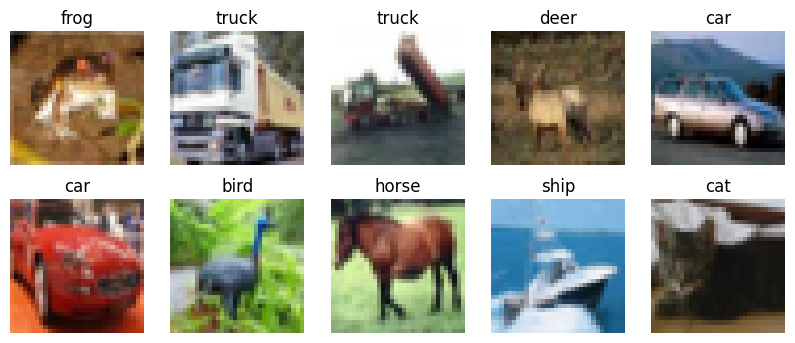

In [3]:
import matplotlib.pyplot as plt #drawing library - draws pictures on screen
import numpy as np #number library - handles grid of numbers

#looking at the picture
#class - list of 10 categories cifar10 - 0-airplane, 1-car, 2-bird ,.......9-truck
classes = [ 'airplane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
#subplot - make a small grid of picture - rows-2, col - 5, (10 categories), figsize - 10-wide 4-tall
fig, axes = plt.subplots(2, 5, figsize = (10,4))#fig- whole page, axes - set of 10 frames
#loop that walks through 10 frames - one by one
#axes.falt - flattens the grid  into a sinlge line, enumerates - i=0, ax- 1st frame
for i, ax in enumerate(axes.flat):
  #take photo i from the teaching set, each item is a pair so this line,unpacks it into img-gets photo, label - number0-9 from training data
  img, label = train_data[i]
  #imshow- draw a picture, insde the current frame
  #img.numpy() - converting pytorch format into numpy values, because the drawing library understands numpy
  #np.transpose --- rreorder the photo dimesions, pytorch stores a photo- color, height, width but numpy stores - height, width, color so transpose reorders
  ax.imshow(np.transpose(img.numpy(),(1,2,0))* 0.5 +0.5)
  #set_title, puts atitle on frame ,by translating a label number as a word
  ax.set_title(classes[label])
  #axis off -hides the little number rulers, so that we can see only the photo
  ax.axis("off")
plt.show()#displays whole pictre







In [4]:
#model build
#torchvision- built in famous models
from torchvision import models
import torch.nn as nn

#picking resnet18 - for pretained weights
#Weights are the knowledge it gained from training on millions of photos. DEFAULT means the standard recommended trained version.
#First run downloads it. model is now the whole network, stored under that name.
model = models.resnet18(weights = models.ResNet18_Weights.DEFAULT)
#param - parameters are signle knbos that are in the networks - millions of knowbs- params--loops each one by one
for param in model.parameters():
  param.requires_grad = False
  #requires_grad means these knobs need  learning? False - no need, whole backbone is frozen/locked ..
  #this is transfer learning : reuse the locked knowledge , and train onlyand train only the new layer
#fc is the final layer, short for fully connected. The old one gave 1000 answers for ImageNet's 1000 classes, so we throw it away and put a fresh one in its place.
#nn.Linear is a simple layer that takes signals in and gives scores out.
#in_features is 512, the number of signals arriving at this layer. 10 is the number of scores it must give out, one per CIFAR-10 class. This new layer starts with random knobs, and it is the only part allowed to learn.
model.fc = nn.Linear(model.fc.in_features, 10)
# Same question as Cell 1, but this time we save the answer in the name device so later lines can use it.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#Move the whole model onto the device, your T4. The model and the photos must live on the same device, otherwise PyTorch gives an error.
model =model.to(device)
print("Model is ready on", device)




Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 178MB/s]


Model is ready on cuda


In [5]:
from torch._dynamo import optimize
#traning ...!
#Data loader is the batch server - hands the photo in small batchs to the model..not whole 50,000 at a time
from torch.utils.data import DataLoader
#loads - train_data(50,000) into batch s of 64, shuffle=true -shuffled into new random epoch, not memorizing
train_loader = DataLoader(train_data, batch_size = 64, shuffle = True)
##loads - test_data(10,000) into batch s of 64, but no shuffling, because testing order doesn't matter and we want it repeatable.
test_loader = DataLoader(test_data, batch_size = 64, shuffle = False)

#creating loss function- --- calculates how wrong the model is ?-compares the model's 10 scores  with the true label and returns one number
#small- good, big- bad
criterion = nn.CrossEntropyLoss()
#Adam optimizer decides how big the loss is ?and nudges
#we give only from final layer knobs to nudge because the rest is frozen
#lr(learning - rate) =0.001 --each step size
optimizer = torch.optim.Adam(model.fc.parameters(), lr =0.001)
epochs = 3 #doing 3 passes
#repeats in 3 passes
for epoch in range(epochs):
  model.train()##puts the model in learning(training) mode
  running_loss = 0.0#total loss so far
  correct = 0#correct gusses so far
  total = 0#photos seen gusses so far

  #takes one batch at a time, 64 images, 64 true labels
  for images, labels in train_loader:
    #move the batch onto the gpu
    images, labels = images.to(device), labels.to(device)
    optimizer.zero_grad() #clearing the previous batch learning signal , otherwisethey pile up
    output = model(images)#the forward pass - photos go through networks - out come 10 score per photo
    #Score the guess, how wrong it is ?
    loss = criterion(output, labels)
    loss.backward()#send back how wrong the signal is to know which knob turn, which way - backpropagation
    optimizer.step()##actually turns the knob , by the amount adam adjusted
    running_loss += loss.item()#Add this batch's loss to the epoch total. .item() pulls the number out of the GPU into a plain number.
    #For each photo, pick the class with the highest score. The underscore means throw away the score value itself, keep only the winning position.
    _, predicted = torch.max(output, 1)

    total += labels.size(0)#add 64 photos seen count
    correct += (predicted == labels).sum().item()# Count how many of this batch's guesses matched the true labels.

  print(f"Epoch {epoch+1}/{epochs} - Loss: ... - Train accuracy: ...%")
    #Prints the epoch's average loss and accuracy. The values inside {} get filled in automatically.





Epoch 1/3 - Loss: ... - Train accuracy: ...%
Epoch 2/3 - Loss: ... - Train accuracy: ...%
Epoch 3/3 - Loss: ... - Train accuracy: ...%


In [6]:
model.eval()#Testing mode. Layers behave for grading, not learning. This matters because ResNet has BatchNorm layers, which use their stored averages in eval mode instead of the current batch's numbers
correct =0
total =0 #Overall counters: correct guesses so far, photos seen so far.
#One counter pair per class. 10 classes, so 10 zeros each
class_correct =[0] * 10
class_total =[0]*10
#Don't track learning signals. Grading never changes the knobs, and skipping the tracking saves memory and speed.
with torch.no_grad():
  #One batch of 64 unseen test photos at a time. These are photos the model never trained on, so this is the honest exam.
  for images, labels in test_loader:
    images, labels = images.to(device), labels.to(device)#Move the batch onto the GPU, same place as the model
    output = model(images) # Forward pass. 10 scores per photo.
    _, predicted = torch.max(output, 1)#Winning class per photo, same as in training.

    total+=labels.size(0)
    correct += (predicted == labels).sum().item()#Same counting as the training cell, but on test photos.

    #The inner for loop sorts each photo's result into its true class's bucket.
    #It counts the photo for that class, and counts it correct only if the guess matched the true label.
    for j in range(labels.size(0)):
      lbl = labels[j].item()
      class_total[lbl] += 1
      if predicted[j].item() == lbl:
        class_correct[lbl] += 1

  print(f"Overall test accuracy: {100*correct/total:.2f}%({correct}/{total})")
  for i, name in enumerate(classes):
    print(f"{name}: {100*class_correct[i]:.2f}%({class_correct[i]}/{class_total[i]})")











Overall test accuracy: 45.31%(4531/10000)
airplane: 48400.00%(484/1000)
car: 51400.00%(514/1000)
bird: 43500.00%(435/1000)
cat: 18400.00%(184/1000)
deer: 49300.00%(493/1000)
dog: 51600.00%(516/1000)
frog: 43200.00%(432/1000)
horse: 44800.00%(448/1000)
ship: 52200.00%(522/1000)
truck: 50300.00%(503/1000)


In [10]:
torch.save(model.state_dict(), 'cifar_resnet18_head.pth')
print("saved")

saved


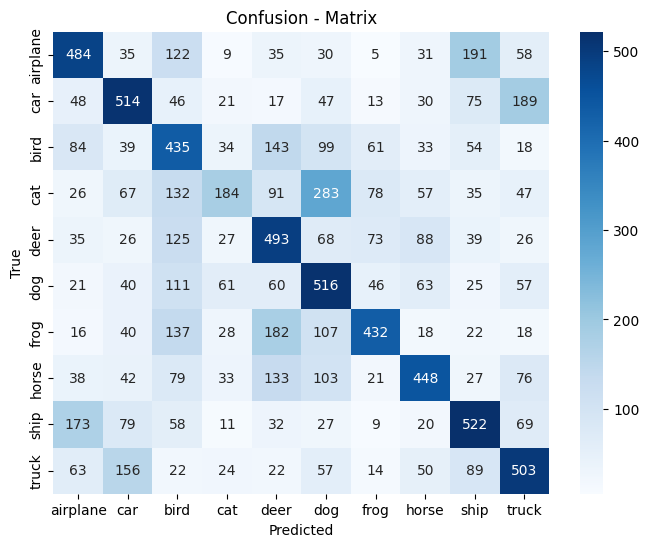

In [11]:
#confusion matrix
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

all_pred = []
all_labels = []
model.eval()
with torch.no_grad():
  for images, labels in test_loader:
    images, labels = images.to(device), labels.to(device)
    outputs = model(images)
    _, predicted = torch.max(outputs, 1)
    all_pred.extend(predicted.cpu().numpy())
    all_labels.extend(labels.cpu().numpy())
cm = confusion_matrix(all_labels, all_pred)
plt.figure(figsize = (8,6))
sns.heatmap(cm, annot = True, fmt ='d', cmap= 'Blues', xticklabels = classes, yticklabels = classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title("Confusion - Matrix")
plt.show()


In [12]:
# calibration - how sure is the model?
import torch.nn.functional as F

threshold = 0.70  # 70% sure or more = auto-decide, below = send to human

auto_correct = 0
auto_total = 0
review_queue = []  # unsure pictures go here

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        probs = F.softmax(outputs, dim=1)  # turn scores into 0-1 probabilities
        conf, predicted = torch.max(probs, 1)  # conf = how sure, predicted = top guess

        for i in range(len(labels)):
            if conf[i] >= threshold:
                auto_total += 1
                if predicted[i] == labels[i]:
                    auto_correct += 1
            else:
                # unsure - save it for human review, with its top guesses
                top_probs, top_idx = torch.topk(probs[i], 3)
                review_queue.append({
                    "true": classes[labels[i]],
                    "guess": classes[predicted[i]],
                    "confidence": round(float(conf[i]), 2),
                    "top3": [classes[j] for j in top_idx.cpu().numpy()]
                })

print("Total pictures:", len(test_loader.dataset))
print("Auto-decided:", auto_total)
print("Sent to human review:", len(review_queue))
print("Accuracy on auto-decided only:", round(100 * auto_correct / auto_total, 2), "%")
print()
print("First 5 in the human review queue:")
for item in review_queue[:5]:
    print(item)


Total pictures: 10000
Auto-decided: 1632
Sent to human review: 8368
Accuracy on auto-decided only: 71.14 %

First 5 in the human review queue:
{'true': 'cat', 'guess': 'bird', 'confidence': 0.39, 'top3': ['bird', 'dog', 'horse']}
{'true': 'ship', 'guess': 'ship', 'confidence': 0.46, 'top3': ['ship', 'airplane', 'truck']}
{'true': 'airplane', 'guess': 'car', 'confidence': 0.46, 'top3': ['car', 'truck', 'ship']}
{'true': 'frog', 'guess': 'deer', 'confidence': 0.34, 'top3': ['deer', 'bird', 'frog']}
{'true': 'frog', 'guess': 'dog', 'confidence': 0.35, 'top3': ['dog', 'deer', 'cat']}


In [13]:
# try different thresholds - coverage vs accuracy
import torch.nn.functional as F

all_conf = []
all_pred = []
all_true = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        probs = F.softmax(outputs, dim=1)
        conf, predicted = torch.max(probs, 1)
        all_conf.extend(conf.cpu().numpy())
        all_pred.extend(predicted.cpu().numpy())
        all_true.extend(labels.cpu().numpy())

print("threshold | auto-decided | sent to review | accuracy on auto-decided")
for t in [0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]:
    auto_idx = [i for i, c in enumerate(all_conf) if c >= t]
    auto_total = len(auto_idx)
    auto_correct = sum(1 for i in auto_idx if all_pred[i] == all_true[i])
    acc = round(100 * auto_correct / auto_total, 2) if auto_total else 0
    print(f"{t:.2f}      | {auto_total:5d}        | {10000 - auto_total:5d}          | {acc}%")

threshold | auto-decided | sent to review | accuracy on auto-decided
0.30      |  7739        |  2261          | 50.19%
0.40      |  5603        |  4397          | 55.85%
0.50      |  3833        |  6167          | 61.07%
0.60      |  2538        |  7462          | 66.59%
0.70      |  1632        |  8368          | 71.14%
0.80      |   926        |  9074          | 75.81%
0.90      |   425        |  9575          | 82.59%


In [14]:
# human review - the human labels the unsure ones, and we save them
import json

threshold = 0.50
review_queue = []

model.eval()
with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(test_loader):
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        probs = F.softmax(outputs, dim=1)
        conf, predicted = torch.max(probs, 1)

        for i in range(len(labels)):
            if conf[i] < threshold:
                # in the notebook, the true label stands in for the human's answer
                # in a real system, a trained expert would type this label
                review_queue.append({
                    "image_index": batch_idx * 64 + i,
                    "true_label": classes[labels[i]],
                    "model_guess": classes[predicted[i]],
                    "confidence": round(float(conf[i]), 2)
                })

# save the human labels for a future batch retrain - NOT for retraining on the test set
with open("human_review_labels.json", "w") as f:
    json.dump(review_queue, f, indent=2)

print("Threshold:", threshold)
print("Sent to human review:", len(review_queue))
print("Saved to: human_review_labels.json")
print()
print("First 3 reviewed:")
for item in review_queue[:3]:
    print(item)
    print("got it, thank for review, i am still learning")


Threshold: 0.5
Sent to human review: 6167
Saved to: human_review_labels.json

First 3 reviewed:
{'image_index': 0, 'true_label': 'cat', 'model_guess': 'bird', 'confidence': 0.39}
got it, thank for review, i am still learning
{'image_index': 2, 'true_label': 'ship', 'model_guess': 'ship', 'confidence': 0.46}
got it, thank for review, i am still learning
{'image_index': 3, 'true_label': 'airplane', 'model_guess': 'car', 'confidence': 0.46}
got it, thank for review, i am still learning


confidence bin | pictures | actual accuracy
0.0-0.1      | 0        | -
0.1-0.2      |   397    | 24.7%
0.2-0.3      |  1864    | 29.5%
0.3-0.4      |  2136    | 35.3%
0.4-0.5      |  1770    | 44.5%
0.5-0.6      |  1295    | 50.3%
0.6-0.7      |   906    | 58.4%
0.7-0.8      |   706    | 65.0%
0.8-0.9      |   501    | 70.1%
0.9-1.0      |   425    | 82.6%


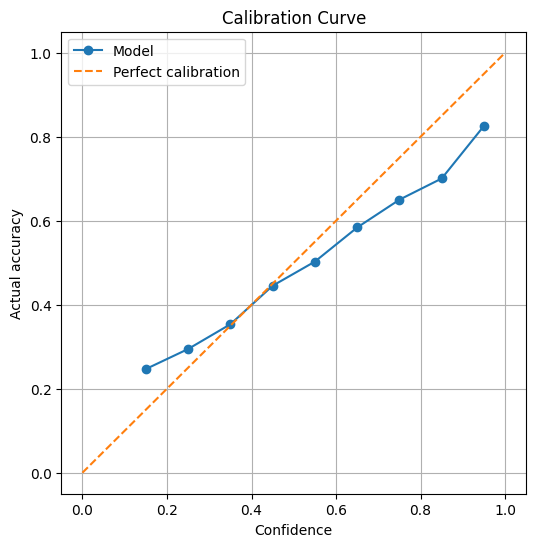

In [15]:
# calibration curve - is the model's confidence honest?
import numpy as np

bins = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

print("confidence bin | pictures | actual accuracy")
bin_centers = []
bin_accs = []
for i in range(10):
    idx = [j for j, c in enumerate(all_conf) if bins[i] <= c < bins[i+1] or (i == 9 and c == 1.0)]
    if idx:
        acc = sum(1 for j in idx if all_pred[j] == all_true[j]) / len(idx)
        bin_centers.append((bins[i] + bins[i+1]) / 2)
        bin_accs.append(acc)
        print(f"{bins[i]:.1f}-{bins[i+1]:.1f}      | {len(idx):5d}    | {round(100*acc, 1)}%")
    else:
        print(f"{bins[i]:.1f}-{bins[i+1]:.1f}      | 0        | -")

plt.figure(figsize=(6, 6))
plt.plot(bin_centers, bin_accs, marker='o', label='Model')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfect calibration')
plt.xlabel('Confidence')
plt.ylabel('Actual accuracy')
plt.title('Calibration Curve')
plt.legend()
plt.grid(True)
plt.show()
